## 3 · Exploratory data analysis (EDA)

### By:
Sofía Arango Patiño

### Date:
2026-11-01

### Description:

Third step of the proof of concept ([issue #3](https://github.com/modsiw-mona/anomaly_detection_ato/issues/3);
CRISP-DM phase 2, *data understanding*; thesis objective OE1, and the hypotheses for OE2).

Works on the typed intermediate dataset from issue #2 (`data/02_intermediate/rba.parquet`). Sections:

1. **Data quality** — types, missing values, duplicates, kinds of noise, and one ID that is not a person.
2. **Univariate** — volume per account, activity over time, categorical distributions, RTT.
3. **Bivariate (versus the takeover label)** — when takeovers happen, and which flags relate to them.
4. **Multivariate — behaviour against the user's own history**, the core hypothesis of the thesis.
5. **Validation rules** for the pipeline, run on all 31.3 M rows.
6. **Decisions and proposals** — final test split (by the rule fixed in the development plan), heuristic models,
   feature engineering needed.

Charts follow one validated palette; every chart has its numbers in a table next to it.

## 📚 Import libraries

In [1]:
import sys
from pathlib import Path

# Make the project's `src/` importable, wherever the notebook is opened from.
REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from matplotlib.ticker import FuncFormatter, PercentFormatter
from pandera.errors import SchemaErrors

from data.datasets import load_dataset_config
from data.intermediate import intermediate_path
from data.validation import validate_intermediate

pl.Config.set_tbl_rows(25)
pl.Config.set_fmt_str_lengths(45)
pl.Config.set_tbl_width_chars(150)

polars.config.Config

Chart style — the reference palette of the project's data-visualisation guide, validated with its script
(categorical slots 1–3 pass every check in light mode; slot 3 sits below 3:1 contrast, so it always carries
labels and a table).

In [3]:
SURFACE, INK, INK_2, MUTED, GRID, AXIS = (
    "#fcfcfb",
    "#0b0b0b",
    "#52514e",
    "#898781",
    "#e1e0d9",
    "#c3c2b7",
)
BLUE, ORANGE = "#2a78d6", "#eb6834"  # categorical slots 1 and 2
CONTEXT_GRAY = "#b9b8b0"  # de-emphasised series in "emphasis" charts

plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "font.family": ["Helvetica Neue", "Arial", "DejaVu Sans"],
        "font.size": 10,
        "text.color": INK,
        "axes.labelcolor": INK_2,
        "axes.edgecolor": AXIS,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "lines.linewidth": 2,
        "legend.frameon": False,
        "figure.dpi": 110,
    }
)


def subtitle(ax: plt.Axes, text: str) -> None:
    ax.text(0, 1.02, text, transform=ax.transAxes, color=INK_2, fontsize=9, va="bottom")


thousands = FuncFormatter(lambda v, _: f"{v / 1e3:,.0f}k")

## 💾 Load data

In [4]:
config = load_dataset_config("rba")
data = pl.read_parquet(intermediate_path(config, REPO_ROOT / "data"))
CATCH_ALL = [int(uid) for uid in config.catch_all_user_ids]  # declared in conf/dataset/rba.yaml
accounts = data.filter(~pl.col("user_id").is_in(CATCH_ALL))  # attempts on real accounts
logins = accounts.filter(pl.col("login_success"))  # the modelling population
print(
    f"all attempts: {data.height:,} | on real accounts: {accounts.height:,} | successful logins: {logins.height:,}"
)

all attempts: 31,269,264 | on real accounts: 17,243,365 | successful logins: 12,541,438


## 🧹 Data quality

### Types and missing values

Types were fixed in issue #2. Missing values after unifying null markers:

In [5]:
pl.DataFrame(
    {
        "field": data.columns,
        "dtype": [str(t) for t in data.dtypes],
        "missing %": [round(100 * data[c].null_count() / data.height, 3) for c in data.columns],
    }
).filter(pl.col("missing %") > 0)

field,dtype,missing %
str,str,f64
"""device_type""","""Categorical""",0.005
"""region""","""Categorical""",44.967
"""city""","""Categorical""",44.495
"""rtt_ms""","""Float64""",95.92


### Duplicates

In [6]:
content = [c for c in data.columns if c != "event_id"]
pl.DataFrame(
    {
        "duplicate kind": ["identical rows (all fields)", "same user and same millisecond"],
        "rows": [
            data.height - data.select(pl.struct(content).n_unique()).item(),
            data.height - data.select(pl.struct("user_id", "timestamp").n_unique()).item(),
        ],
    }
)

duplicate kind,rows
str,i64
"""identical rows (all fields)""",0
"""same user and same millisecond""",0


### One ID is not a person

The number of attempts per user ID is extremely skewed. The largest IDs:

In [7]:
top_ids = (
    data.group_by("user_id")
    .agg(
        pl.len().alias("attempts"),
        pl.col("login_success").sum().alias("successes"),
        pl.col("label_ato").sum().alias("takeovers"),
        pl.col("label_attack_ip").mean().mul(100).round(1).alias("attack IP %"),
        (pl.col("device_type") == "bot").mean().mul(100).round(1).alias("bot %"),
        pl.col("country").n_unique().alias("countries"),
        pl.col("asn").n_unique().alias("ASNs"),
    )
    .sort("attempts", descending=True)
    .head(5)
    .with_columns((100 * pl.col("attempts") / data.height).round(2).alias("% of all rows"))
)
top_ids

user_id,attempts,successes,takeovers,attack IP %,bot %,countries,ASNs,% of all rows
i64,u32,u32,u32,f64,f64,u32,u32,f64
-4324475583306591935,14025899,4,0,11.8,14.5,227,11694,44.86
6998943612473066845,70028,2,0,0.0,0.0,1,1,0.22
-7198559811247368245,6417,5972,0,96.9,0.0,1,1,0.02
-4652302824165996131,1927,1820,0,0.3,0.0,16,55,0.01
-2894367365566592989,1613,1550,0,0.0,0.0,1,1,0.01


- **The first ID is not a person**: 14 M attempts (45% of all rows) and only 4 successes, from 227 countries
  and ~11,700 networks, with 14% bots, spanning the whole period. It is almost certainly a **bucket for attempts
  against accounts that could not be identified**. It is declared in the translation file as
  `catch_all_user_ids`: kept in the data, excluded from anything "per user" — and from the rest of this
  analysis, where `accounts` means real accounts only.
- It also **confounds** simple statistics: it holds 75% of all failed attempts. Issue #2 initially reported that
  placeholder IPs are twice as frequent in failed logins; that was this ID (corrected in #2):

In [8]:
(
    data.with_columns(pl.col("user_id").is_in(CATCH_ALL).alias("catch-all ID"))
    .group_by("catch-all ID", "login_success")
    .agg(
        pl.len().alias("attempts"),
        pl.col("ip_is_placeholder").mean().mul(100).round(1).alias("placeholder IP %"),
    )
    .sort("catch-all ID", "login_success")
)

catch-all ID,login_success,attempts,placeholder IP %
bool,bool,u32,f64
false,false,4701927,10.8
false,true,12541438,15.3
true,false,14025895,34.7
true,true,4,0.0


- The second ID is a single account hit 70,028 times from 4 IPs with 2 successes — scripted guessing or a
  misconfigured client — and is **not** labelled as a takeover.
- The third is a very active real account (≈6,000 successes) whose logins come **97% from "attack IPs"** and
  that has **no** takeover: a shared IP (VPN, proxy, cloud) that ended up on blocklists. A live example that an
  attack IP is not a takeover.

### Kinds of noise

| Kind | Where | Size | Treatment |
| --- | --- | --- | --- |
| Catch-all user ID | `user_id` | 14.0 M rows (45%) | Excluded from per-user behaviour (config `catch_all_user_ids`) |
| Placeholder IP (synthesis) | `ip` ∈ 10.0.0.0/8 | 7.3 M rows (23%) | Flag `ip_is_placeholder`; ablation in issue #6 |
| Placeholder ASN (synthesis) | `asn` ≥ 500000 | 1.5 M rows (4.7%) | Flag `asn_is_placeholder`; ablation in issue #6 |
| Null marker `-` | `region`, `city` | ~14 M rows each | Real nulls (issue #2) |
| Unparseable user agent | `device_type` null | 1,526 rows | Kept as null (authors' README) |
| Mostly missing measurement | `rtt_ms` | 96% missing | See RTT below |
| Automated clients | `device_type = bot` | 2.0 M rows | Kept: bots almost never succeed |
| Single-account guessing | 2nd ID above | 70 k rows | Kept: real behaviour |
| Attack-IP list noise | 3rd ID above | 6 k successes | Kept; shows `Is Attack IP` is a proxy |
| Takeover on a failed login | `label_ato` | 1 row | Warning-level validation rule |

## 📊 Univariate analysis

### Attempts per account

In [9]:
per_account = accounts.group_by("user_id").agg(
    pl.len().alias("attempts"), pl.col("login_success").sum().alias("successes")
)
quantiles = [0.5, 0.75, 0.9, 0.99, 0.999]
pl.DataFrame(
    {
        "measure": ["attempts per account", "successes per account (accounts with ≥1)"],
        **{
            f"p{q * 100:g}": [
                per_account["attempts"].quantile(q),
                per_account.filter(pl.col("successes") > 0)["successes"].quantile(q),
            ]
            for q in quantiles
        },
        "max": [per_account["attempts"].max(), per_account["successes"].max()],
    }
)

measure,p50,p75,p90,p99,p99.9,max
str,f64,f64,f64,f64,f64,i64
"""attempts per account""",2.0,4.0,9.0,28.0,84.0,70028
"""successes per account (accounts with ≥1)""",2.0,4.0,8.0,28.0,88.0,5972


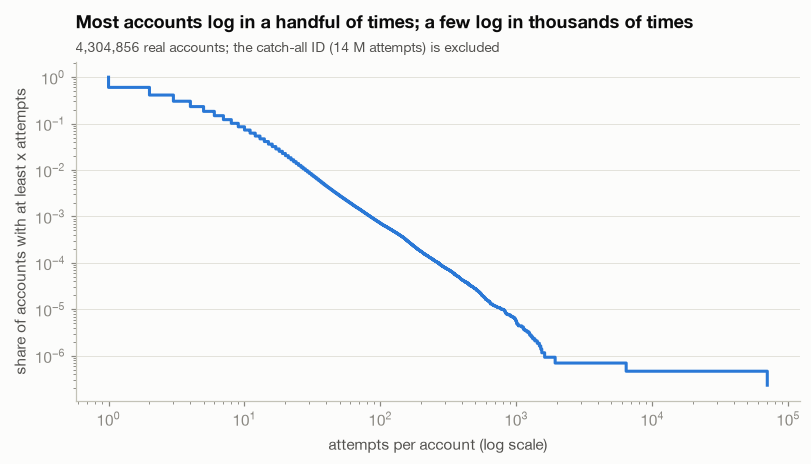

In [10]:
counts = np.sort(per_account["attempts"].to_numpy())
share_at_least = 1 - np.arange(counts.size) / counts.size  # P(attempts >= x)

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.step(counts, share_at_least, where="post", color=BLUE)
ax.set_xscale("log")
ax.set_yscale("log")
ax.grid(axis="y")
ax.set_xlabel("attempts per account (log scale)")
ax.set_ylabel("share of accounts with at least x attempts")
ax.set_title("Most accounts log in a handful of times; a few log in thousands of times", pad=22)
subtitle(ax, f"{per_account.height:,} real accounts; the catch-all ID (14 M attempts) is excluded")
plt.show()

### Activity over time

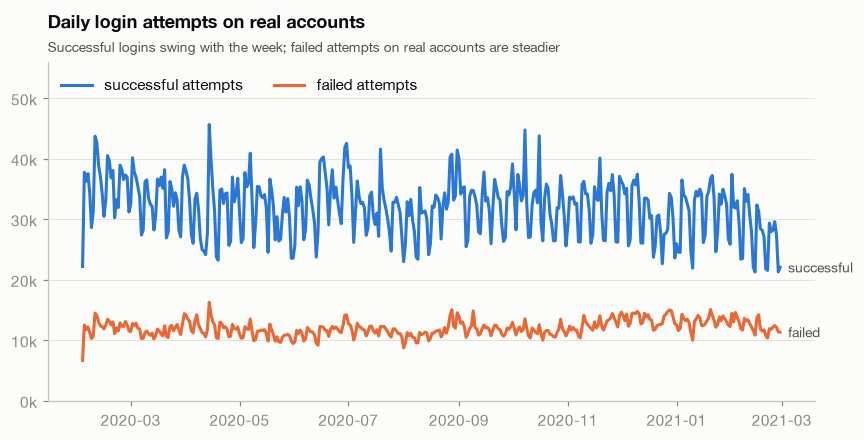

mean successful/day,mean failed/day,max failed/day,busiest failed day
f64,f64,u32,date
31993.0,11995.0,16232,2020-04-14


In [11]:
daily = (
    accounts.group_by(pl.col("timestamp").dt.date().alias("day"))
    .agg(
        pl.col("login_success").sum().alias("successful"),
        (~pl.col("login_success")).sum().alias("failed"),
    )
    .sort("day")
)
fig, ax = plt.subplots(figsize=(9, 4))
for column, color in (("successful", BLUE), ("failed", ORANGE)):
    ax.plot(daily["day"], daily[column], color=color, label=f"{column} attempts")
    ax.text(
        daily["day"][-1], daily[column][-1], f"  {column}", color=INK_2, va="center", fontsize=9
    )
ax.yaxis.set_major_formatter(thousands)
ax.set_ylim(0, 56_000)
ax.grid(axis="y")
ax.legend(loc="upper left", ncols=2)
ax.set_title("Daily login attempts on real accounts", pad=22)
subtitle(ax, "Successful logins swing with the week; failed attempts on real accounts are steadier")
plt.show()
daily.select(
    pl.col("successful").mean().round(0).alias("mean successful/day"),
    pl.col("failed").mean().round(0).alias("mean failed/day"),
    pl.col("failed").max().alias("max failed/day"),
    pl.col("day")
    .filter(pl.col("failed") == pl.col("failed").max())
    .first()
    .alias("busiest failed day"),
)

### Categorical distributions

In [12]:
(
    accounts.group_by("device_type")
    .agg(
        pl.len().alias("attempts"),
        pl.col("login_success").mean().mul(100).round(2).alias("success %"),
        pl.col("label_attack_ip").mean().mul(100).round(1).alias("attack IP %"),
    )
    .sort("attempts", descending=True)
)

device_type,attempts,success %,attack IP %
cat,u32,f64,f64
"""mobile""",11558229,66.88,11.6
"""desktop""",5095786,85.13,1.9
"""tablet""",575752,80.34,2.2
"""unknown""",13370,83.99,0.9
null,129,48.06,23.3
"""bot""",99,64.65,9.1


In [13]:
(
    logins.group_by("country")
    .agg(pl.len().alias("successful logins"))
    .sort("successful logins", descending=True)
    .with_columns((100 * pl.col("successful logins") / logins.height).round(2).alias("share %"))
    .head(10)
)

country,successful logins,share %
cat,u32,f64
"""NO""",8656556,69.02
"""US""",2102566,16.76
"""BR""",371458,2.96
"""PL""",354317,2.83
"""GB""",225883,1.8
"""UA""",124622,0.99
"""IN""",115012,0.92
"""DE""",108641,0.87
"""AU""",97029,0.77


### Round-trip time (RTT)

Present for only a small share of attempts — and for a single confirmed takeover:

In [14]:
pl.DataFrame(
    {
        "population": ["all attempts", "successful logins", "confirmed takeovers"],
        "RTT present %": [
            round(100 * data["rtt_ms"].is_not_null().mean(), 2),
            round(100 * logins["rtt_ms"].is_not_null().mean(), 2),
            round(100 * logins.filter("label_ato")["rtt_ms"].is_not_null().mean(), 2),
        ],
    }
)

population,RTT present %
str,f64
"""all attempts""",4.08
"""successful logins""",6.98
"""confirmed takeovers""",0.71


In [15]:
logins["rtt_ms"].drop_nulls().describe()

statistic,value
str,f64
"""count""",875234.0
"""null_count""",0.0
"""mean""",629.895351
"""std""",787.674674
"""min""",9.0
"""25%""",470.0
"""50%""",535.0
"""75%""",668.0
"""max""",223457.0


## 📊 Bivariate analysis — against the takeover label

### When do takeovers happen?

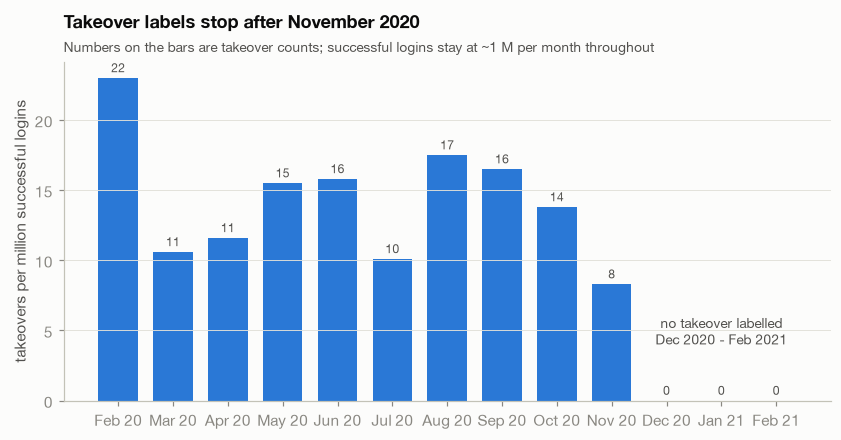

month,successful logins,takeovers,per million
datetime[ms],u32,u32,f64
2020-02-01 00:00:00,956760,22,23.0
2020-03-01 00:00:00,1040118,11,10.6
2020-04-01 00:00:00,950387,11,11.6
2020-05-01 00:00:00,969517,15,15.5
2020-06-01 00:00:00,1011607,16,15.8
2020-07-01 00:00:00,991213,10,10.1
2020-08-01 00:00:00,970147,17,17.5
2020-09-01 00:00:00,972641,16,16.5
2020-10-01 00:00:00,1014050,14,13.8


In [16]:
monthly = (
    logins.group_by(pl.col("timestamp").dt.truncate("1mo").alias("month"))
    .agg(pl.len().alias("successful logins"), pl.col("label_ato").sum().alias("takeovers"))
    .sort("month")
    .with_columns(
        (1e6 * pl.col("takeovers") / pl.col("successful logins")).round(1).alias("per million")
    )
)
fig, ax = plt.subplots(figsize=(9, 4))
labels = monthly["month"].dt.strftime("%b %y").to_list()
bars = ax.bar(labels, monthly["per million"], color=BLUE, width=0.72)
ax.bar_label(
    bars, labels=[str(n) for n in monthly["takeovers"]], color=INK_2, fontsize=8, padding=2
)
ax.grid(axis="y")
ax.set_ylabel("takeovers per million successful logins")
ax.set_title("Takeover labels stop after November 2020", pad=22)
subtitle(
    ax,
    "Numbers on the bars are takeover counts; successful logins stay at ~1 M per month throughout",
)
ax.text(11, 4, "no takeover labelled\nDec 2020 - Feb 2021", ha="center", color=INK_2, fontsize=9)
plt.show()
monthly

Successful logins stay at ~1 M per month, but **no takeover is labelled after November 2020**. Attacks do
not plausibly stop overnight for three months; the more likely explanation is that **labelling stopped** — the
incident-response records that produced the labels end there. Logins from December 2020 to February 2021 are
therefore **unlabelled, not clean**. This matters for the final split (see *Decisions*).

### Which flags relate to takeovers?

Takeover rate per 100,000 successful logins, with and without each condition:

In [17]:
conditions = {
    "attack IP": pl.col("label_attack_ip"),
    "placeholder IP": pl.col("ip_is_placeholder"),
    "placeholder ASN": pl.col("asn_is_placeholder"),
    "region missing": pl.col("region").is_null(),
    "city missing": pl.col("city").is_null(),
    "RTT missing": pl.col("rtt_ms").is_null(),
    "device = mobile": pl.col("device_type") == "mobile",
    "country ≠ NO": pl.col("country") != "NO",
}
rows = []
for name, condition in conditions.items():
    with_c = logins.filter(condition)
    without = logins.filter(~condition)
    rate_with = 1e5 * with_c["label_ato"].mean()
    rate_without = 1e5 * without["label_ato"].mean()
    rows.append(
        {
            "condition": name,
            "logins with it %": round(100 * with_c.height / logins.height, 1),
            "takeovers with it": with_c["label_ato"].sum(),
            "rate with (per 100k)": round(rate_with, 2),
            "rate without (per 100k)": round(rate_without, 2),
            "ratio": round(rate_with / rate_without, 1),
        }
    )
pl.DataFrame(rows).sort("ratio", descending=True)

condition,logins with it %,takeovers with it,rate with (per 100k),rate without (per 100k),ratio
str,f64,i64,f64,f64,f64
"""country ≠ NO""",31.0,130,3.35,0.12,29.0
"""attack IP""",6.4,76,9.45,0.55,17.3
"""RTT missing""",93.0,139,1.19,0.11,10.4
"""placeholder ASN""",4.1,12,2.36,1.06,2.2
"""placeholder IP""",15.3,39,2.03,0.95,2.1
"""region missing""",37.6,75,1.59,0.83,1.9
"""city missing""",37.0,74,1.6,0.84,1.9
"""device = mobile""",61.6,20,0.26,2.49,0.1


## 🧭 Multivariate analysis — behaviour against the user's own history

The thesis rests on one hypothesis: **a takeover login looks unusual *for that user***. Testing it needs, for
each successful login, what that user had done **before** it — never after.

### Sample

Computing every user's history is the job of the feature pipeline (issue #4). Here a **user-based sample** is
enough: every account with a takeover plus 20,000 random accounts with at least one success (fixed seed), each
with its **complete** history — sampling users, not rows, so no history has holes.

In [18]:
SEED, N_USERS = 20261101, 20_000
takeover_users = logins.filter("label_ato")["user_id"].unique()
candidates = np.sort(logins["user_id"].unique().to_numpy())
sampled = np.random.default_rng(SEED).choice(candidates, size=N_USERS, replace=False)
sample_users = np.union1d(sampled, takeover_users.to_numpy())

history = accounts.filter(pl.col("user_id").is_in(sample_users)).sort("user_id", "timestamp")
failed = (~pl.col("login_success")).cast(pl.Int32)
for period in (
    "1h",
    "24h",
):  # failed attempts on the same account in the window ending at each attempt
    window = (
        history.with_columns(failed.alias("failed"))
        .rolling(index_column="timestamp", period=period, group_by="user_id")
        .agg(pl.col("failed").sum().alias(f"fails_{period}"))
    )
    history = history.with_columns(window[f"fails_{period}"])

SIGNALS = ["ip", "asn", "country", "region", "city", "device_type", "os", "browser", "user_agent"]
READABLE = {
    "ip": "IP",
    "asn": "ASN",
    "device_type": "device type",
    "os": "OS",
    "user_agent": "user agent",
}
behaviour = history.filter("login_success").with_columns(
    pl.int_range(pl.len()).over("user_id").alias("prior_successes"),
    # first time this user succeeds with this value (rows are in time order within each user)
    *(pl.col(s).is_first_distinct().over("user_id").alias(f"new {s}") for s in SIGNALS),
)
print(
    f"sample: {sample_users.size:,} accounts, {history.height:,} attempts, "
    f"{behaviour.height:,} successful logins ({behaviour['label_ato'].sum()} takeovers)"
)

sample: 20,134 accounts, 98,222 attempts, 79,326 successful logins (140 takeovers)


### Novelty: takeovers versus legitimate logins

Only logins **with a history** (at least one earlier successful login) — "new for this user" is undefined on a
first login.

In [19]:
with_history = behaviour.filter(pl.col("prior_successes") >= 1)
extra = {
    "≥1 failed attempt, previous hour": pl.col("fails_1h") >= 1,
    "≥1 failed attempt, previous 24 h": pl.col("fails_24h") >= 1,
    "attack IP": pl.col("label_attack_ip"),
}
rows = []
for name, expr in [
    *((f"new {READABLE.get(s, s)}", pl.col(f"new {s}")) for s in SIGNALS),
    *extra.items(),
]:
    rates = with_history.group_by("label_ato").agg(expr.mean().alias("rate")).sort("label_ato")
    legit, takeover = rates["rate"].to_list()
    rows.append(
        {
            "signal": name,
            "legitimate %": round(100 * legit, 1),
            "takeover %": round(100 * takeover, 1),
            "ratio": round(takeover / legit, 1),
        }
    )
novelty = pl.DataFrame(rows).sort("ratio")
print(
    f"{with_history.height - with_history['label_ato'].sum():,} legitimate logins "
    f"vs {with_history['label_ato'].sum()} takeovers with history"
)
novelty.sort("ratio", descending=True)

59,106 legitimate logins vs 86 takeovers with history


signal,legitimate %,takeover %,ratio
str,f64,f64,f64
"""new country""",1.0,80.2,83.2
"""attack IP""",5.6,54.7,9.7
"""new ASN""",10.4,86.0,8.3
"""new device type""",8.3,31.4,3.8
"""new region""",21.8,65.1,3.0
"""new city""",26.9,66.3,2.5
"""new IP""",40.9,96.5,2.4
"""new OS""",22.0,46.5,2.1
"""new browser""",37.9,76.7,2.0


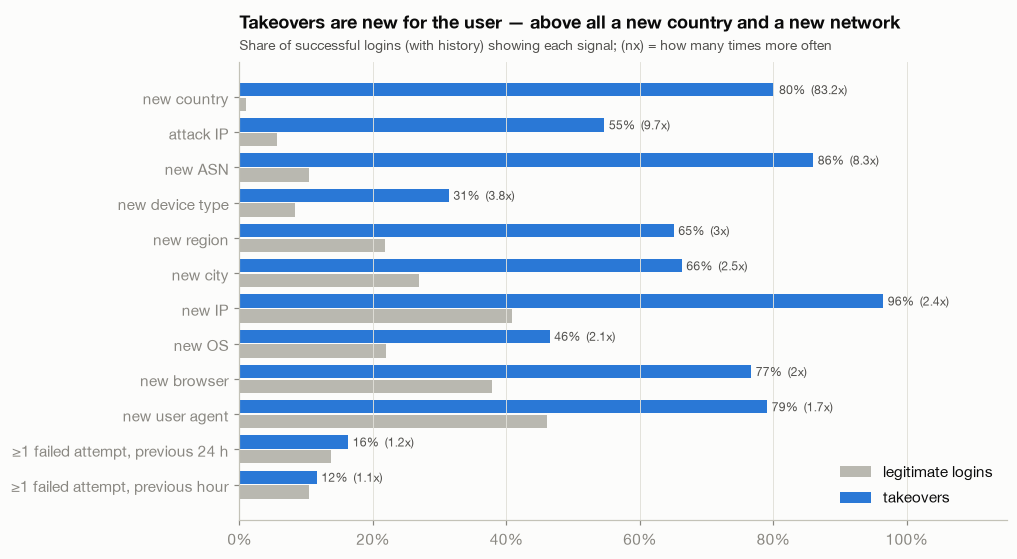

In [20]:
fig, ax = plt.subplots(figsize=(9, 5.4))
y = np.arange(novelty.height)
height = 0.38
ax.barh(
    y - height / 2 - 0.02,
    novelty["legitimate %"],
    height,
    color=CONTEXT_GRAY,
    label="legitimate logins",
)
bars = ax.barh(y + height / 2 + 0.02, novelty["takeover %"], height, color=BLUE, label="takeovers")
ax.bar_label(
    bars,
    labels=[
        f"{v:.0f}%  ({r:g}x)" for v, r in zip(novelty["takeover %"], novelty["ratio"], strict=True)
    ],
    color=INK_2,
    fontsize=8,
    padding=3,
)
ax.set_yticks(y, novelty["signal"])
ax.xaxis.set_major_formatter(PercentFormatter())
ax.set_xlim(0, 115)
ax.grid(axis="x")
ax.legend(loc="lower right")
ax.set_title("Takeovers are new for the user — above all a new country and a new network", pad=22)
subtitle(
    ax,
    "Share of successful logins (with history) showing each signal; (nx) = how many times more often",
)
plt.show()

### Several signals at once

In [21]:
key = ["asn", "country", "device_type", "os", "browser"]
(
    with_history.with_columns(
        pl.sum_horizontal(*(pl.col(f"new {s}").cast(pl.Int8) for s in key)).alias(
            "new signals (of 5)"
        )
    )
    .group_by("new signals (of 5)")
    .agg(
        (~pl.col("label_ato")).sum().alias("legitimate"),
        pl.col("label_ato").sum().alias("takeovers"),
    )
    .sort("new signals (of 5)")
    .with_columns(
        (100 * pl.col("legitimate") / pl.col("legitimate").sum()).round(1).alias("legitimate %"),
        (100 * pl.col("takeovers") / pl.col("takeovers").sum()).round(1).alias("takeovers %"),
    )
)

new signals (of 5),legitimate,takeovers,legitimate %,takeovers %
i8,u32,u32,f64,f64
0,33943,11,57.4,12.8
1,11483,3,19.4,3.5
2,7357,8,12.4,9.3
3,4683,24,7.9,27.9
4,1488,15,2.5,17.4
5,152,25,0.3,29.1


### Cold start: takeovers without history

How much history does a user have when the takeover happens?

In [22]:
DEEP_HISTORY = 5  # earlier successful logins
takeovers = behaviour.filter("label_ato")
pl.DataFrame(
    {
        "earlier successful logins": [
            "0 (first ever)",
            f"1 to {DEEP_HISTORY - 1}",
            f"{DEEP_HISTORY} or more",
        ],
        "takeovers": [
            (takeovers["prior_successes"] == 0).sum(),
            takeovers["prior_successes"].is_between(1, DEEP_HISTORY - 1).sum(),
            (takeovers["prior_successes"] >= DEEP_HISTORY).sum(),
        ],
    }
).with_columns((100 * pl.col("takeovers") / takeovers.height).round(1).alias("%"))

earlier successful logins,takeovers,%
str,i64,f64
"""0 (first ever)""",54,38.6
"""1 to 4""",52,37.1
"""5 or more""",34,24.3


What distinguishes a takeover on a **first** login from a legitimate first login? Only global signals are available:

In [23]:
first = behaviour.filter(pl.col("prior_successes") == 0)
(
    first.group_by("label_ato")
    .agg(
        pl.len().alias("first logins"),
        pl.col("label_attack_ip").mean().mul(100).round(1).alias("attack IP %"),
        (pl.col("country") != "NO").mean().mul(100).round(1).alias("country ≠ NO %"),
        pl.col("ip_is_placeholder").mean().mul(100).round(1).alias("placeholder IP %"),
        pl.col("region").is_null().mean().mul(100).round(1).alias("region missing %"),
        (pl.col("device_type") == "mobile").mean().mul(100).round(1).alias("mobile %"),
    )
    .sort("label_ato")
)

label_ato,first logins,attack IP %,country ≠ NO %,placeholder IP %,region missing %,mobile %
bool,u32,f64,f64,f64,f64,f64
false,20080,10.7,50.4,12.1,49.1,76.5
true,54,53.7,94.4,29.6,44.4,18.5


## ✅ Data validation rules

The rules every later stage can rely on, written as a Pandera schema (`src/data/validation.py`):

- **Generic** (from the standard schema): storage type of every column; required fields and labels never null;
  `event_id` unique; artefact flags never null; no unexpected column.
- **Dataset-specific** (`validation` section of `conf/dataset/rba.yaml`, each backed by a measurement above or
  in notebook 2): timestamp in [2020-02-01, 2021-03-01); one row per user and millisecond; `device_type` in
  {mobile, desktop, tablet, bot, unknown}; `country` matches `^[A-Z]{2}$`; `asn` made of digits; `rtt_ms` in
  [1, 8,600,000] ms.
- **Warning-level**: a confirmed takeover sits on a successful login — reported, not fatal (one known exception).

Run on the full dataset:

In [24]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    try:
        validate_intermediate(data, config)
        print(f"All error-level rules pass on {data.height:,} rows.")
    except SchemaErrors as errors:
        print("Validation failed:")
        print(errors.failure_cases.group_by("check", "column").len())
for warning in caught:
    print("warning:", str(warning.message).split(" failure case")[0])
data.filter(pl.col("label_ato") & ~pl.col("login_success")).select(
    "event_id", "timestamp", "country", "device_type", "label_attack_ip"
)

All error-level rules pass on 31,269,264 rows.


event_id,timestamp,country,device_type,label_attack_ip
u32,datetime[ms],cat,cat,bool
10227169,2020-06-24 12:41:30.353,"""RO""","""desktop""",true


## 🧾 Decisions

### Final test split — the rule fixed in the development plan

The plan (section 5.2) fixed the rule **before** looking at the data: *time-based split if the last ~20% of the
timeline holds at least 20 takeovers; otherwise a random 20% split, grouped by user and stratified by label.*

In [25]:
MIN_TEST_TAKEOVERS = 20  # development plan, section 5.2
cutoff = logins.select(pl.col("timestamp").quantile(0.8, interpolation="nearest")).item()
after = logins.filter(pl.col("timestamp") > cutoff)["label_ato"].sum()
decision = (
    "time-based split"
    if after >= MIN_TEST_TAKEOVERS
    else "random split, grouped by user, stratified by label"
)
print(f"80th percentile of successful-login time: {cutoff:%Y-%m-%d}")
print(f"takeovers after it: {after} (rule needs >= {MIN_TEST_TAKEOVERS})  ->  {decision}")

80th percentile of successful-login time: 2020-12-06
takeovers after it: 0 (rule needs >= 20)  ->  random split, grouped by user, stratified by label


**Outcome: random split, grouped by user, stratified by label** — the last 20% of the timeline (from
December 2020) holds **no** takeover. The rule is applied as written.

**Label window — decided.** Because labels end in November 2020, logins from December 2020 – February 2021 are
*unlabelled*: kept in the evaluation, any takeover among them would count as a legitimate login and bias every
precision figure down. This was raised as stop point 1 of the development plan, and **the thesis author decided
(2026-11-01) to score and evaluate only logins from February to November 2020**; later months may still feed
past-only history features. It is implemented in issue #4 as `label_window` in the translation file.

| Option | What it means | Outcome |
| --- | --- | --- |
| **A. Label window Feb – Nov 2020** | Only logins from the labelled period are scored and evaluated | **Chosen** |
| B. Keep all 13 months | Evaluate on everything | Rejected: Dec – Feb would count possible takeovers as legitimate |

### Heuristic models worth testing

1. **The Freeman et al. (2016) RBA score** — the established method; it compares how often each IP / ASN /
   country / user-agent value appears in the user's history versus globally. This EDA shows those exact signals
   carry the strongest separation, so it is a demanding baseline.
2. **"New country for this user"** — a single rule flagging 80% of takeovers that have a history while firing on
   1% of legitimate logins in the sample.
3. **"Attack IP"** — flags 55% of takeovers with history (9.7× legitimate) and works on first logins too;
   combined with rule 2 it covers both history and cold-start cases.

These become the baselines in issue #5 (dummy + heuristic) — measured properly there, with the evaluation
protocol, not on this sample.

### Feature engineering needed (issue #4)

- **Per-user novelty**, computed only from the past: new country, new ASN, new IP, new device type, new OS, new
  browser, new user agent, new region/city — plus how many are new at once.
- **History depth**: number of earlier successful logins, time since the previous one (cold start must be
  visible to the model).
- **Global rarity**: how common the country / ASN / device / user agent is across *all* users up to that moment —
  the only signals for the 39% of takeovers on a first login.
- **Attack-IP flag** and **missingness indicators** (`region`, `city`).
- **Placeholder flags**: kept as features only behind the ablation of issue #6, since they are generation
  artefacts that correlate with the label.
- **Exclude** the catch-all ID from per-user features; keep RTT out unless its ablation shows value (present for
  one takeover only).

## 📊 Analysis of Results and Conclusions

- **Data quality is good, with one structural surprise.** No duplicates of any kind; all formats valid; every
  validation rule passes on 31.3 M rows. But **one user ID is a catch-all**, holding 45% of all rows and 75% of
  failed attempts. It confounded a conclusion of issue #2 (corrected there) and must be excluded from anything
  "per user".
- **Labels end in November 2020.** No takeover is labelled in the last three months although login volume is
  unchanged. The pre-registered split rule therefore gives a *random, user-grouped* split, and evaluation is
  restricted to the labelled window (Feb – Nov 2020), as decided by the thesis author.
- **The thesis hypothesis holds strongly.** Among logins with history, a takeover comes from a **new country
  80% of the time versus 1% for legitimate logins (×83)**, from a new network 86% vs 10% (×8), from an attack IP
  55% vs 6% (×10). Several new signals at once are rare for legitimate users and common for takeovers.
- **Not every expected signal is there.** Failed attempts on the same account just before a takeover are barely
  more frequent than before a legitimate login (×1.1–1.2): the attackers here mostly had the right credentials,
  so the classic credential-stuffing burst is not a useful per-account signal in this dataset.
- **Cold start is large.** **39% of takeovers happen on the user's first successful login**, where "new for this
  user" says nothing. Global signals (attack IP, rarity, country) must carry those cases; this shapes the feature
  set and is a finding worth stating in the thesis.
- **RTT is not usable for takeovers** (present for one of 140). **Placeholder artefacts correlate with the label**
  (about ×2), so they stay behind an ablation.
- **`Is Attack IP` is a noisy proxy**: a very active legitimate account logs in almost only from "attack IPs",
  yet it is the strongest *global* signal for takeovers. Using it as a feature is reasonable; using it as the
  target is not.

## 💡 Proposals and Ideas

- **Label window decided** (Feb – Nov 2020): issue #4 builds the modelling dataset on it.
- **Issue #4:** implement the per-user and global features in a streaming, past-only way over the full timeline,
  with unit tests on hand-built histories (no peeking at the future); then the user-grouped split.
- **Issue #5:** dummy baseline + Freeman RBA score + the two single-signal rules above, under the full evaluation
  protocol (repeated grouped CV, PR-AUC, recall at alert budgets).
- **Thesis text:** the catch-all ID, the end of labels in November 2020 and the 87-vs-140 discrepancy are dataset
  findings worth reporting as such.

## 📖 References

- Wiefling, S., Jørgensen, P. R., Thunem, S., & Lo Iacono, L. (2022). Pump Up Password Security! *ACM TOPS*,
  26(1). https://doi.org/10.1145/3546069
- Freeman, D., Jain, S., Dürmuth, M., Biggio, B., & Giacinto, G. (2016). Who Are You? A Statistical Approach to
  Measuring User Authenticity. *NDSS*. https://doi.org/10.14722/ndss.2016.23240
- Pandera documentation (polars backend): https://pandera.readthedocs.io/
- Course methodology — EDA: https://joserzapata.github.io/post/ciencia-datos-proyecto-python/3-analysis/